In [ ]:
import json
import logging
import os
import requests

logging.basicConfig(
    level=logging.INFO, format="%(asctime)s - %(levelname)s - %(message)s"
)

OPENROUTER_API_KEY = os.getenv(
    "OPENROUTER_API_KEY",
    "",
)
DECISIONS_URL = "https://openrouter.ai/api/alpha/decisions"


class RiskAnalysisModule:

    def __init__(self, api_key: str = None):
        self.api_key = (
            api_key or os.getenv("OPENROUTER_API_KEY") or OPENROUTER_API_KEY
        )

        self.headers = {
            "Authorization": f"Bearer {self.api_key}",
            "Content-Type": "application/json",
            "X-OpenRouter-Title": "Insurance Fraud Risk Layer",
        }

    @staticmethod
    def save_model(output_path: str = "outputs/risk_model.json"):
        """Optional static method to save module configuration if needed."""
        print("RiskAnalysisModule configuration verified.")
        return output_path

    @classmethod
    def load_module(cls, api_key: str = None):
        """Loads the module and initializes operational core using standard class conventions."""
        instance = cls(api_key=api_key)
        print("RiskAnalysisModule loaded successfully.")
        return instance

    def _build_jev_request(self, payload: dict) -> dict:
        """Constructs JEV decision questions linking ValidationImage, PoliMi AI Score, and Consistency Layer outputs."""
        return {
            "model": "~typesafe/jev-latest",
            "state": payload,
            "questions": {
                "is_visible_ghost_billing": {
                    "type": "choice",
                    "instructions": (
                        "Analyze missing parts. Are there visible outer structural"
                        " body parts (e.g., doors, roof, roof panel, fenders,"
                        " quarter panel) billed strictly in the invoice without"
                        " proof in photos/police?"
                    ),
                    "criteria": {
                        "TRUE": (
                            "Yes, unverified visible outer structural parts exist"
                            " in invoice."
                        ),
                        "FALSE": (
                            "No, all visible parts are verified or discrepancies"
                            " are purely internal/non-structural."
                        ),
                    },
                },
                "ai_image_threat": {
                    "type": "choice",
                    "instructions": (
                        "Inspect 'images_analysis' array in state. Evaluate PoliMi"
                        " score S or ai_level: S >= 1.00 (or ai_level == 3) is HIGH"
                        " risk; 0.05 <= S < 1.00 (or ai_level == 2) is MILD risk; S"
                        " < 0.05 (or ai_level == 1) is NONE."
                    ),
                    "criteria": {
                        "AI_RISK_HIGH": (
                            "At least one image has PoliMi score S >= 1.00 or"
                            " ai_level == 3."
                        ),
                        "AI_RISK_MILD": (
                            "No image has S >= 1.00, but at least one image has"
                            " 0.05 <= S < 1.00 or ai_level == 2."
                        ),
                        "AI_RISK_NONE": (
                            "All images have S < 0.05 or ai_level == 1 OR"
                            " 'images_analysis' is missing/empty."
                        ),
                    },
                },
                "vehicle_detection_status": {
                    "type": "choice",
                    "instructions": (
                        "Inspect 'images_analysis' array in state. Evaluate vehicle"
                        " detection results from ValidationImage (vehicle_detected"
                        " and vehicle_confidence). Flag NO_VEHICLE_DETECTED if"
                        " vehicle_detected is False or vehicle_confidence < 0.05"
                        " (conf threshold)."
                    ),
                    "criteria": {
                        "NO_VEHICLE_DETECTED": (
                            "At least one image has vehicle_detected == False or"
                            " vehicle_confidence < 0.05."
                        ),
                        "LOW_CONFIDENCE": (
                            "Vehicle detected, but vehicle_confidence is between"
                            " 0.05 and 0.20."
                        ),
                        "VEHICLE_CONFIRMED": (
                            "All images have vehicle_detected == True and"
                            " vehicle_confidence >= 0.20 OR 'images_analysis' is"
                            " missing/empty."
                        ),
                    },
                },
                "risk_level": {
                    "type": "choice",
                    "instructions": (
                        "Evaluate overall risk level considering text consistency,"
                        " AI image threat (PoliMi Feature), and vehicle detection"
                        " confidence (ValidationImage)."
                    ),
                    "criteria": {
                        "HIGH": (
                            "ai_image_threat is AI_RISK_HIGH OR"
                            " is_visible_ghost_billing is TRUE OR"
                            " overall_consistency_score < 0.60 OR"
                            " vehicle_detection_status is NO_VEHICLE_DETECTED."
                        ),
                        "MEDIUM": (
                            "ai_image_threat is AI_RISK_MILD OR"
                            " vehicle_detection_status is LOW_CONFIDENCE OR"
                            " internal structural ghost billing exists OR"
                            " overall_consistency_score is between 0.60 and 0.79."
                        ),
                        "LOW": (
                            "ai_image_threat is AI_RISK_NONE AND"
                            " vehicle_detection_status is VEHICLE_CONFIRMED AND no"
                            " ghost billing AND overall_consistency_score >= 0.80."
                        ),
                    },
                },
            },
        }

    def evaluate_claim(self, payload: dict) -> dict:
        """Evaluates the claim using JEV for semantic reasoning.

        In case of API communication failure, automatically falls back to manual human review.
        """
        try:
            req_body = self._build_jev_request(payload)
            response = requests.post(
                DECISIONS_URL, headers=self.headers, json=req_body, timeout=10
            )

            if response.status_code == 200:
                res_data = response.json().get("answers", {})

                risk_choice = res_data.get("risk_level", {}).get("choice", "MEDIUM")
                ai_threat = res_data.get("ai_image_threat", {}).get(
                    "choice", "AI_RISK_NONE"
                )
                vehicle_status = res_data.get("vehicle_detection_status", {}).get(
                    "choice", "VEHICLE_CONFIRMED"
                )
                jev_has_ghost_visible = (
                    res_data.get("is_visible_ghost_billing", {}).get("choice") == "TRUE"
                )

                # Decision logic based on JEV analysis
                if (
                    risk_choice == "HIGH"
                    or ai_threat == "AI_RISK_HIGH"
                    or jev_has_ghost_visible
                    or vehicle_status == "NO_VEHICLE_DETECTED"
                ):
                    action = "REJECT_AND_REFER_TO_SIU"
                    risk_choice = "HIGH"
                elif (
                    risk_choice == "MEDIUM"
                    or ai_threat == "AI_RISK_MILD"
                    or vehicle_status == "LOW_CONFIDENCE"
                ):
                    action = "MANUAL_HUMAN_REVIEW"
                    risk_choice = "MEDIUM"
                else:
                    action = "APPROVE_OR_FAST_TRACK"
                    risk_choice = "LOW"

                return {
                    "predicted_risk": risk_choice,
                    "recommended_action": action,
                    "jev_evaluations": {
                        "ai_image_threat": ai_threat,
                        "vehicle_detection_status": vehicle_status,
                        "visible_ghost_billing_detected": jev_has_ghost_visible,
                    },
                }
            else:
                logging.warning(
                    f"Jev API returned HTTP {response.status_code}. Executing"
                    " Fallback."
                )

        except Exception as e:
            logging.error(
                f"Error communicating with Jev API: {e}. Executing Fallback."
            )

        # Emergency Fallback
        return {
            "predicted_risk": "MEDIUM",
            "recommended_action": "MANUAL_HUMAN_REVIEW",
            "jev_evaluations": {
                "status": "FALLBACK_DUE_TO_API_FAILURE",
                "message": (
                    "JEV Service unavailable. Claim safely routed to Manual Human"
                    " Review."
                ),
            },
        }

    def get_risk_info(self, consistency_info: dict, validation_scores) -> str:
        """Receives consistency_info and validation_scores outputs, combines and evaluates them via JEV,

        and returns the final result as a formatted JSON String.
        """
        payload = {}

        # 1. Merge consistency_info data
        if isinstance(consistency_info, dict):
            payload.update(consistency_info)

        # 2. Merge validation_scores into images_analysis array
        if isinstance(validation_scores, list):
            payload["images_analysis"] = validation_scores
        elif isinstance(validation_scores, dict):
            if "images_analysis" in validation_scores:
                payload["images_analysis"] = validation_scores["images_analysis"]
            else:
                payload["images_analysis"] = [validation_scores]

        # 3. Calculate risk level and decision via JEV
        result_dict = self.evaluate_claim(payload)

        # 4. Return result as JSON String
        return json.dumps(result_dict, indent=2, ensure_ascii=False)


# Example Usage
if __name__ == "__main__":
    # 1. Load class via load_module
    risk_module = RiskAnalysisModule.load_module()

    # 2. Sample data payload
    sample_consistency = {
        "claim_id": "CLM-REAL-019",
        "ground_truth_risk": "HIGH",
        "ground_truth_fraud": 1,
        "annotation_rationale": "Claim requesting replacement of vehicle roof panel and windshield frame following a side mirror scratch.",
        "payload": {
            
            # Consistency Layer Outputs
            "user_description_invoice": {
                "matches": [
                    { "User Description": "Door Mirror", "Invoice": "Side Mirror" }
                ],
                "consistent_parts": ["Side Mirror"],
                "inconsistent_parts": ["Roof Outer Panel"],
                "is_car_info_consistent": False,
                "missings": [
                    { "part": "Roof Outer Panel", "only_in": "Invoice" },
                    { "part": "Windshield Frame", "only_in": "Invoice" }
                ],
                "consistency_score": 0.35
            },
            "image_invoice": {
                "matches": [
                    { "image": "Door Mirror", "invoice": "Side Mirror" }
                ],
                "consistent_parts": ["Side Mirror"],
                "inconsistent_parts": [],
                "missings": [
                    { "part": "Roof Outer Panel", "only_in": "invoice" }
                ],
                "consistency_score": 0.3
            },
            "ivoice_police_report": {
                "matches": [
                    { "invoice": "Side Mirror", "police_report": "Mirror Scratch" }
                ],
                "consistent_parts": ["Side Mirror"],
                "inconsistent_parts": [],
                "is_car_info_consistent": False,
                "missings": [
                    { "part": "Roof Outer Panel", "only_in": "Invoice" }
                ],
                "consistency_score": 0.32
            },
            "image_user_description": {
                "matches": [
                    { "image": "Door Mirror", "user_description": "Door Mirror" }
                ],
                "consistent_parts": ["Door Mirror"],
                "inconsistent_parts": [],
                "missings": [],
                "consistency_score": 0.5
            },
            "user_description_police_report": {
                "matches": [
                    { "user_description": "Door Mirror", "police_report": "Mirror Scratch" }
                ],
                "consistent_parts": ["Door Mirror"],
                "inconsistent_parts": [],
                "is_car_info_consistent": False,
                "missings": [],
                "consistency_score": 0.42
            },
            "image_police_report": {
                "matches": [
                    { "image": "Door Mirror", "police_report": "Mirror Scratch" }
                ],
                "consistent_parts": ["Mirror Scratch"],
                "inconsistent_parts": [],
                "missings": [],
                "consistency_score": 0.4
            },
            "overall_consistency_score": 0.382
        }
    }

    sample_validation = [
        {
            "image_name": "side_mirror_damage.jpg",
            "vehicle_detected": True,
            "vehicle_confidence": 0.942,  # Confidence score from ValidationImage
            "S": 0.01,                    # PoliMi AI Score (Real image, non-AI)
            "ai_level": 1
        }
    ]

    # 3. Call method and retrieve result string
    risk_result_str = risk_module.get_risk_info(
        sample_consistency, sample_validation
    )

    print("\n--- Output (Returned String) ---")
    print(risk_result_str)

RiskAnalysisModule loaded successfully.

--- Output (Returned String) ---
{
  "predicted_risk": "HIGH",
  "recommended_action": "REJECT_AND_REFER_TO_SIU",
  "jev_evaluations": {
    "ai_image_threat": "AI_RISK_NONE",
    "vehicle_detection_status": "VEHICLE_CONFIRMED",
    "visible_ghost_billing_detected": true
  }
}


In [10]:
import json

# 1. Load original dataset
file_path = "/kaggle/input/datasets/nataliemmoris/dataset40sample/40.json"
with open(file_path, "r", encoding="utf-8") as f:
  raw_data = json.load(f)

unlabeled_data = []
ground_truths = {}

for claim in raw_data:
  ref = claim.get("claim_reference")
  gt = claim.get("ground_truth")

  # Store ground truth separately for evaluation
  ground_truths[ref] = gt

  # Create a copy of the claim and remove ground truth fields
  claim_copy = claim.copy()
  claim_copy.pop("ground_truth", None)
  claim_copy.pop("ground_truth_reason", None)

  unlabeled_data.append(claim_copy)

# 2. Save cleaned test input file
output_path = "claims_test_input.json"
with open(output_path, "w", encoding="utf-8") as f:
  json.dump(unlabeled_data, f, ensure_ascii=False, indent=2)

print(
    f"Clean test input file created successfully without ground truth:"
    f" {output_path}"
)

Clean test input file created successfully without ground truth: claims_test_input.json


RiskAnalysisModule loaded successfully.
Starting model evaluation on 40 claims...

Overall Model Accuracy: 85.00%



/tmp/ipykernel_49/1238355485.py:180: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


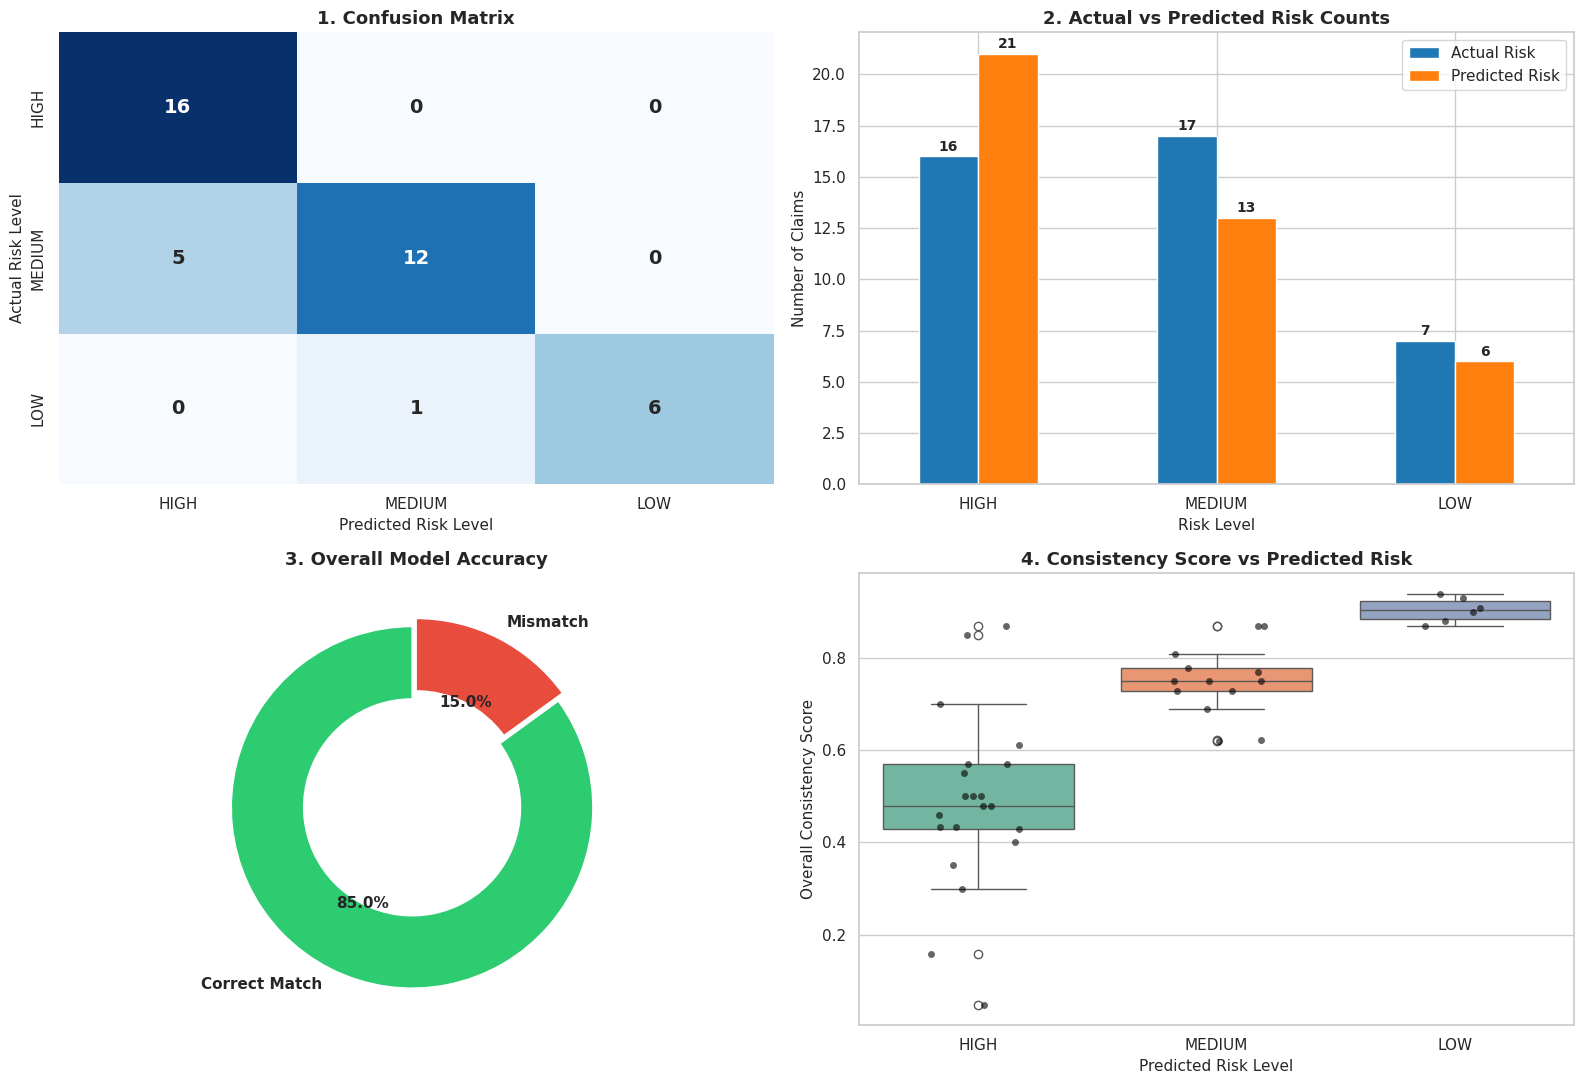


Classification Report:
              precision    recall  f1-score   support

        HIGH       0.76      1.00      0.86        16
      MEDIUM       0.92      0.71      0.80        17
         LOW       1.00      0.86      0.92         7

    accuracy                           0.85        40
   macro avg       0.89      0.85      0.86        40
weighted avg       0.87      0.85      0.85        40



In [12]:
import json
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Set aesthetic style for plots
sns.set_theme(style="whitegrid")

# 1. Load and initialize the module
risk_module = RiskAnalysisModule.load_module()

# 2. Read dataset (40 claims)
file_path = "/kaggle/input/datasets/nataliemmoris/dataset40sample/40.json"  # Kaggle path

with open(file_path, "r", encoding="utf-8") as f:
    data = json.load(f)

results = []

print(f"Starting model evaluation on {len(data)} claims...\n")

# 3. Iterate and evaluate each claim
for idx, claim in enumerate(data):
    claim_ref = claim.get("claim_reference", f"CLM-{idx+1}")
    actual_ground_truth = claim.get("ground_truth", "UNKNOWN")

    # A) Extract consistency layer data
    consistency_info = (
        claim.get("state") or claim.get("consistency_output") or {}
    )
    overall_cs = consistency_info.get("overall_consistency_score", None)

    # B) Extract or construct image validation payload
    if "images_analysis" in consistency_info:
        validation_scores = consistency_info["images_analysis"]
    elif "images_analysis" in claim:
        validation_scores = claim["images_analysis"]
    else:
        ai_score = claim.get("ai_image_score", 0.0)
        v_conf = claim.get("vehicle_confidence", 1.0)

        if ai_score >= 1.0:
            ai_lvl = 3
        elif ai_score >= 0.05:
            ai_lvl = 2
        else:
            ai_lvl = 1

        validation_scores = [{
            "image_name": f"{claim_ref}_img.jpg",
            "vehicle_detected": v_conf >= 0.05,
            "vehicle_confidence": v_conf,
            "S": ai_score,
            "ai_level": ai_lvl,
        }]

    # C) Call module to evaluate claim
    try:
        eval_result_str = risk_module.get_risk_info(
            consistency_info, validation_scores
        )
        eval_json = json.loads(eval_result_str)

        predicted_risk = eval_json.get("predicted_risk", "ERROR")
        rec_action = eval_json.get("recommended_action", "N/A")
    except Exception as e:
        predicted_risk = "ERROR"
        rec_action = str(e)

    is_match = predicted_risk == actual_ground_truth

    results.append({
        "Index": idx + 1,
        "Claim Reference": claim_ref,
        "Actual (Ground Truth)": actual_ground_truth,
        "Predicted Risk": predicted_risk,
        "Match": "PASS" if is_match else "FAIL",
        "Is_Correct": is_match,
        "Consistency_Score": overall_cs,
        "Recommended Action": rec_action,
    })

# 4. Results summary and accuracy calculation
results_df = pd.DataFrame(results)

y_true = results_df["Actual (Ground Truth)"].tolist()
y_pred = results_df["Predicted Risk"].tolist()

accuracy = accuracy_score(y_true, y_pred)

print(
    "=========================================================================="
)
print(f"Overall Model Accuracy: {accuracy * 100:.2f}%")
print(
    "==========================================================================\n"
)

# 5. Build Visualization Dashboard
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
labels = ["HIGH", "MEDIUM", "LOW"]

# Chart 1: Confusion Matrix
cm = confusion_matrix(y_true, y_pred, labels=labels)
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels,
    ax=axes[0, 0],
    cbar=False,
    annot_kws={"size": 14, "weight": "bold"},
)
axes[0, 0].set_title(
    "1. Confusion Matrix", fontsize=13, fontweight="bold"
)
axes[0, 0].set_xlabel("Predicted Risk Level", fontsize=11)
axes[0, 0].set_ylabel("Actual Risk Level", fontsize=11)

# Chart 2: Actual vs Predicted Distribution
df_counts = pd.DataFrame({
    "Actual Risk": (
        pd.Series(y_true).value_counts().reindex(labels, fill_value=0)
    ),
    "Predicted Risk": (
        pd.Series(y_pred).value_counts().reindex(labels, fill_value=0)
    ),
})
df_counts.plot(kind="bar", ax=axes[0, 1], color=["#1f77b4", "#ff7f0e"])
axes[0, 1].set_title(
    "2. Actual vs Predicted Risk Counts",
    fontsize=13,
    fontweight="bold",
)
axes[0, 1].set_xlabel("Risk Level", fontsize=11)
axes[0, 1].set_ylabel("Number of Claims", fontsize=11)
axes[0, 1].tick_params(axis="x", rotation=0)

for p in axes[0, 1].patches:
    if p.get_height() > 0:
        axes[0, 1].annotate(
            str(int(p.get_height())),
            (p.get_x() + p.get_width() / 2.0, p.get_height()),
            ha="center",
            va="bottom",
            fontsize=10,
            fontweight="bold",
            xytext=(0, 2),
            textcoords="offset points",
        )

# Chart 3: Accuracy Match Pie / Donut Chart
match_counts = results_df["Is_Correct"].value_counts()
match_labels = (
    ["Correct Match", "Mismatch"]
    if len(match_counts) > 1
    else ["Correct Match"]
)
colors = ["#2ecc71", "#e74c3c"]
axes[1, 0].pie(
    match_counts,
    labels=match_labels,
    autopct="%1.1f%%",
    startangle=90,
    colors=colors,
    explode=(0.05, 0) if len(match_counts) > 1 else None,
    wedgeprops=dict(width=0.4),
    textprops={"fontsize": 11, "weight": "bold"},
)
axes[1, 0].set_title(
    "3. Overall Model Accuracy", fontsize=13, fontweight="bold"
)

# Chart 4: Consistency Score Distribution by Predicted Risk
df_valid_cs = results_df.dropna(subset=["Consistency_Score"])
if not df_valid_cs.empty:
    sns.boxplot(
        x="Predicted Risk",
        y="Consistency_Score",
        data=df_valid_cs,
        order=labels,
        ax=axes[1, 1],
        palette="Set2",
    )
    sns.stripplot(
        x="Predicted Risk",
        y="Consistency_Score",
        data=df_valid_cs,
        order=labels,
        ax=axes[1, 1],
        color="black",
        alpha=0.6,
        jitter=0.2,
    )
    axes[1, 1].set_title(
        "4. Consistency Score vs Predicted Risk",
        fontsize=13,
        fontweight="bold",
    )
    axes[1, 1].set_xlabel("Predicted Risk Level", fontsize=11)
    axes[1, 1].set_ylabel("Overall Consistency Score", fontsize=11)
else:
    axes[1, 1].text(
        0.5,
        0.5,
        "No Consistency Scores Available",
        ha="center",
        va="center",
        fontsize=12,
    )

plt.tight_layout()
plt.show()

# 6. Detailed Classification Report
print("\nClassification Report:")
print(
    classification_report(
        y_true, y_pred, labels=["HIGH", "MEDIUM", "LOW"], zero_division=0
    )
)